# Proyecto: Machine Learning y Deep Learning Aplicados (UTEC)
## Tarea 1: Clasificación de Imágenes en Food-101 (101 Clases)
**Profesor:** Marcelo Jafett Contreras Cabrera  
**Entorno de Ejecución:** Local con aceleración GPU (PyTorch AMP FP16/TF32)

---
### 1. Definición del Problema Matemático
Se busca aprender un mapeo paramétrico $f_\theta: \mathcal{X} \to \mathcal{Y}$, donde $\mathcal{X} \subset \mathbb{R}^{H \times W \times 3}$ es el espacio de imágenes de alimentos y $\mathcal{Y} = \{0, 1, \dots, 100\}$ representa las 101 clases gastronómicas.
El objetivo es encontrar los pesos óptimos $\theta^*$ que minimizan la función de pérdida de entropía cruzada categórica (Categorical Cross-Entropy):
$$\mathcal{L}_{CE}(\theta) = -\frac{1}{N} \sum_{i=1}^N \sum_{c=1}^{C} y_{i,c} \log(\hat{y}_{i,c})$$
donde $\hat{y}_{i,c} = \frac{e^{z_{i,c}}}{\sum_{j=1}^C e^{z_{i,j}}}$ es la distribución softmax estimada.


In [1]:
# 1. Configuración de Hardware y Reproducibilidad
import sys
import os
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Agregar Cod/src al path
sys.path.append(os.path.abspath("../src"))

from config import setup_hardware, set_seed, FOOD101_DIR, CHECKPOINTS_DIR
from metrics import compute_classification_metrics, plot_confusion_matrix, print_metrics_summary
from visualize import plot_convergence_curves, plot_latent_space, extract_torch_embeddings
from trainer import Trainer
from data_vision import create_food101_dataloaders
from models_vision import FoodVisionBaseline, FoodVisionAdvanced, SimpleGradCAM

# Inicializar optimizaciones de GPU (TF32, cuDNN Benchmark) y fijar semilla aleatoria
hw_info = setup_hardware()
set_seed(42)


[Hardware] GPU Detectada: NVIDIA GeForce RTX 5070
[Hardware] VRAM Total: 11.58 GB | Capacidad de Cómputo: sm_120
[Hardware] TF32 habilitado: True
[Hardware] cuDNN Benchmark habilitado: True
[Hardware] CPU Cores: 24 | Workers recomendados para DataLoader: 8
[Reproducibilidad] Semilla establecida en: 42


---
### 2. Preprocesamiento de Datos y Data Augmentation (Sección 5.1)
El preprocesamiento consiste en:
1. **Redimensionamiento y Recorte:** Redimensionamiento y recorte aleatorio a $224 \times 224$ píxeles (`RandomResizedCrop`).
2. **Data Augmentation:** `RandAugment` con transformaciones aleatorias (rotaciones, cambios de brillo, contraste y traslaciones) y volteo horizontal (`RandomHorizontalFlip`).
3. **Normalización:** Estandarización de canales utilizando las medias y desviaciones de ImageNet:
   $$\mu = [0.485, 0.456, 0.406], \quad \sigma = [0.229, 0.224, 0.225]$$
4. **DataLoaders Eficientes:** `num_workers=4`, `pin_memory=True` para transferencias directas DMA a la memoria VRAM de la GPU.


In [2]:
# 2. Carga del Dataset Food-101 y DataLoaders
# NOTA: subset_fraction=1.0 usa todo el dataset (101,000 imágenes).
# Puedes usar subset_fraction=0.1 para pruebas y depuración ultra rápidas.
SUBSET_FRACTION = 1.0  
BATCH_SIZE = 64

train_loader, val_loader, test_loader, class_names = create_food101_dataloaders(
    root_dir=FOOD101_DIR,
    batch_size=BATCH_SIZE,
    img_size=224,
    num_workers=hw_info["recommended_workers"],
    subset_fraction=SUBSET_FRACTION
)

print(f"Número total de clases: {len(class_names)}")
print(f"Batches de entrenamiento: {len(train_loader)} | Validación: {len(val_loader)} | Prueba: {len(test_loader)}")


[Food-101] Dataset completo: Train=68,175, Val=7,575, Test=25,250
Número total de clases: 101
Batches de entrenamiento: 1066 | Validación: 119 | Prueba: 395


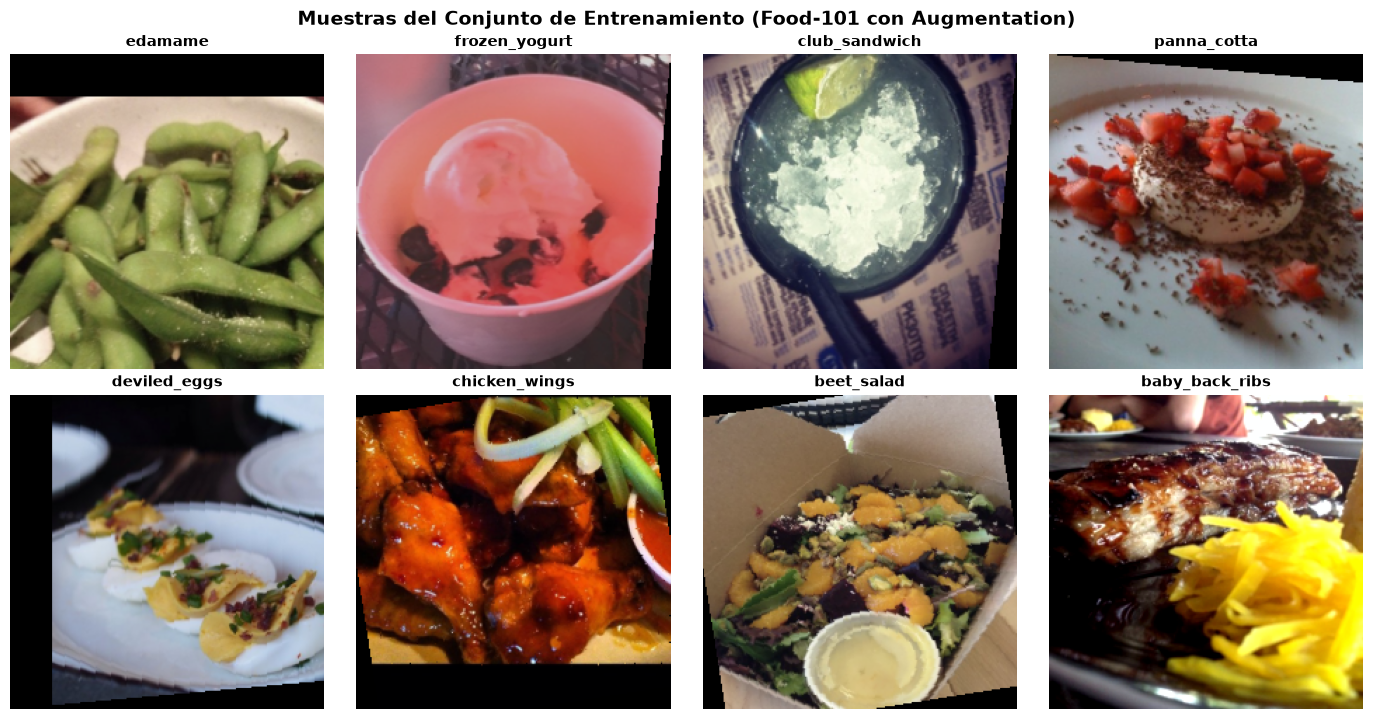

In [3]:
# Visualización de un batch de imágenes con sus etiquetas
images, labels = next(iter(train_loader))

plt.figure(figsize=(14, 7))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    # Desnormalizar para visualización
    img = images[i].permute(1, 2, 0).numpy()
    img = np.clip(img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406], 0, 1)
    plt.imshow(img)
    plt.title(class_names[labels[i].item()], fontsize=11, fontweight='bold')
    plt.axis("off")
plt.tight_layout()
plt.suptitle("Muestras del Conjunto de Entrenamiento (Food-101 con Augmentation)", y=1.02, fontsize=14, fontweight='bold')
plt.show()


---
### 3. Metodología: Comparación de Dos Algoritmos (Sección 4)

#### **Método 1: Baseline Ligero (ResNet-18)**
* **Espacio de Hipótesis:** Red residual profunda con conexiones de salto $y = \mathcal{F}(x, \{W_i\}) + x$, agrupamiento global (Global Average Pooling) y clasificador lineal con dropout ($p=0.2$).
* **Optimizador:** Adam ($lr = 10^{-3}$) o SGD con momentum ($0.9$), weight decay $10^{-4}$.
* **Supuestos:** Las representaciones jerárquicas aprendidas en ImageNet son transferibles a la clasificación de alimentos sin desvanecimiento de gradiente.

#### **Método 2: Deep Learning Avanzado (EfficientNet-B0)**
* **Espacio de Hipótesis:** Bloques MBConv (Mobile Inverted Bottleneck Convolution) optimizados mediante búsqueda de arquitectura neuronal (NAS) y escalamiento compuesto uniforme de profundidad, ancho y resolución.
* **Optimizador:** AdamW con regularización por decaimiento de pesos desacoplado ($lr = 5 \times 10^{-4}$) y Cosine Annealing Learning Rate Scheduler.
* **Regularización Adicional:** Dropout ($p=0.3$) y Label Smoothing ($\alpha = 0.1$).


In [4]:
# 3. Método 1: Entrenamiento del Baseline ResNet-18
model_baseline = FoodVisionBaseline(num_classes=101, pretrained=True, freeze_backbone=False)
optimizer_baseline = torch.optim.Adam(model_baseline.parameters(), lr=1e-3, weight_decay=1e-4)
criterion_baseline = torch.nn.CrossEntropyLoss()

trainer_baseline = Trainer(
    model=model_baseline,
    optimizer=optimizer_baseline,
    criterion=criterion_baseline,
    device=hw_info["device"],
    use_amp=hw_info["use_amp"],
    checkpoint_dir=CHECKPOINTS_DIR,
    model_name="food101_resnet18_baseline"
)

# Entrenar modelo
EPOCHS = 10
history_baseline = trainer_baseline.fit(train_loader, val_loader, epochs=EPOCHS, early_stopping_patience=3)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/nvm/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:02<00:00, 22.8MB/s]



[Trainer] Iniciando entrenamiento por 10 épocas...
[Trainer] Dispositivo: cuda | Mixed Precision (AMP): True



Training:   0%|          | 0/1066 [00:00<?, ?it/s]

Época [01/10] (63.0s) | LR: 0.001000 | Train Loss: 2.8390 - Acc: 31.63% | Val Loss: 2.5537 - Acc: 38.52%
  --> ¡Nuevo mejor modelo guardado en /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/food101_resnet18_baseline.pt! (Val Acc: 38.52%)


...

Época [08/10] (36.5s) | LR: 0.001000 | Train Loss: 1.5295 - Acc: 60.30% | Val Loss: 1.6249 - Acc: 59.33%


Training:   0%|          | 0/1066 [00:00<?, ?it/s]

Época [09/10] (36.8s) | LR: 0.001000 | Train Loss: 1.4938 - Acc: 61.18% | Val Loss: 1.5449 - Acc: 61.50%
  --> ¡Nuevo mejor modelo guardado en /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/food101_resnet18_baseline.pt! (Val Acc: 61.50%)


Training:   0%|          | 0/1066 [00:00<?, ?it/s]

Época [10/10] (36.8s) | LR: 0.001000 | Train Loss: 1.4595 - Acc: 61.88% | Val Loss: 1.5649 - Acc: 60.37%
[Trainer] Cargados los mejores pesos de /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/food101_resnet18_baseline.pt


In [5]:
# 4. Método 2: Entrenamiento del Modelo Avanzado EfficientNet-B0
model_advanced = FoodVisionAdvanced(num_classes=101, pretrained=True, dropout=0.3)
optimizer_advanced = torch.optim.AdamW(model_advanced.parameters(), lr=5e-4, weight_decay=1e-2)
scheduler_advanced = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_advanced, T_max=EPOCHS, eta_min=1e-6)
# Cross-Entropy con Label Smoothing (Sección 3.1)
criterion_advanced = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

trainer_advanced = Trainer(
    model=model_advanced,
    optimizer=optimizer_advanced,
    criterion=criterion_advanced,
    scheduler=scheduler_advanced,
    device=hw_info["device"],
    use_amp=hw_info["use_amp"],
    checkpoint_dir=CHECKPOINTS_DIR,
    model_name="food101_efficientnet_advanced"
)

# Entrenar modelo avanzado
history_advanced = trainer_advanced.fit(train_loader, val_loader, epochs=EPOCHS, early_stopping_patience=3)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /home/nvm/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 113MB/s]



[Trainer] Iniciando entrenamiento por 10 épocas...
[Trainer] Dispositivo: cuda | Mixed Precision (AMP): True



Training:   0%|          | 0/1066 [00:00<?, ?it/s]

Época [01/10] (88.4s) | LR: 0.000488 | Train Loss: 2.3067 - Acc: 56.29% | Val Loss: 1.7333 - Acc: 72.71%
  --> ¡Nuevo mejor modelo guardado en /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/food101_efficientnet_advanced.pt! (Val Acc: 72.71%)


...

Época [08/10] (61.8s) | LR: 0.000049 | Train Loss: 1.1382 - Acc: 90.86% | Val Loss: 1.4241 - Acc: 81.65%


Training:   0%|          | 0/1066 [00:00<?, ?it/s]

Época [09/10] (61.4s) | LR: 0.000013 | Train Loss: 1.0934 - Acc: 92.43% | Val Loss: 1.4135 - Acc: 82.10%
  --> ¡Nuevo mejor modelo guardado en /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/food101_efficientnet_advanced.pt! (Val Acc: 82.10%)


Training:   0%|          | 0/1066 [00:00<?, ?it/s]

Época [10/10] (61.4s) | LR: 0.000001 | Train Loss: 1.0688 - Acc: 93.43% | Val Loss: 1.4120 - Acc: 82.19%
  --> ¡Nuevo mejor modelo guardado en /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/food101_efficientnet_advanced.pt! (Val Acc: 82.19%)
[Trainer] Cargados los mejores pesos de /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/food101_efficientnet_advanced.pt


---
### 4. Análisis de Convergencia (Sección 5.4)
Se presentan las curvas de pérdida y exactitud a lo largo de las épocas para entrenamiento y validación.
Se analiza:
* Presencia de **overfitting** (brecha entre curvas de train y val).
* Estabilidad del entrenamiento con optimizadores Adam vs AdamW + Cosine Scheduler.
* Beneficio del escalado de gradientes y precisión mixta (AMP).


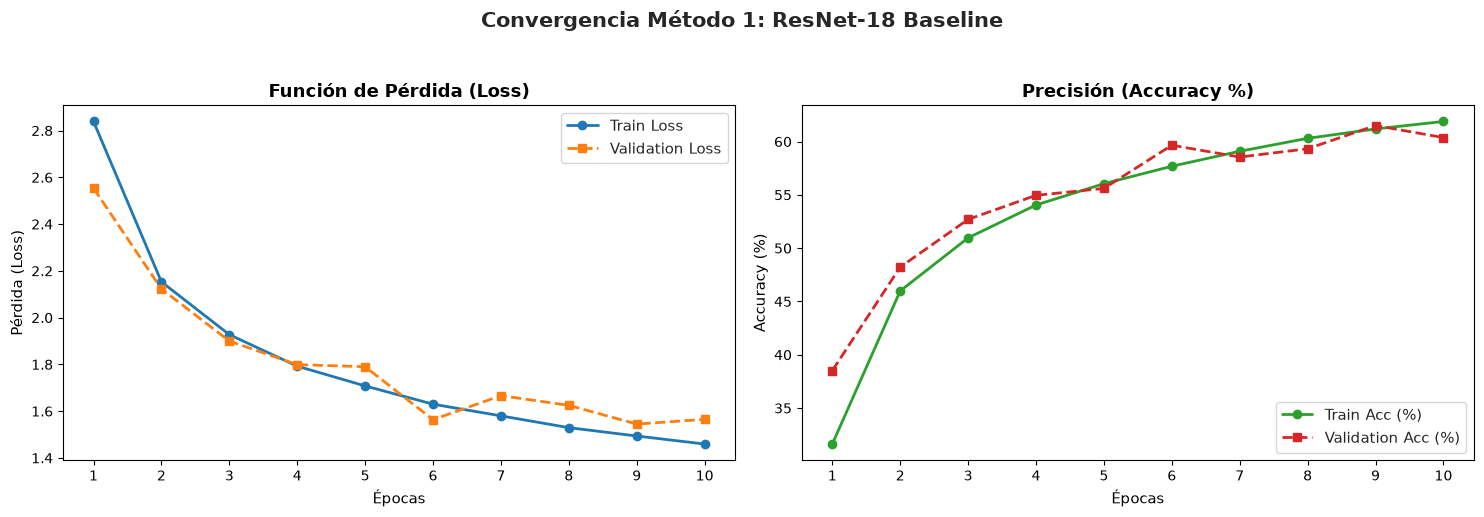

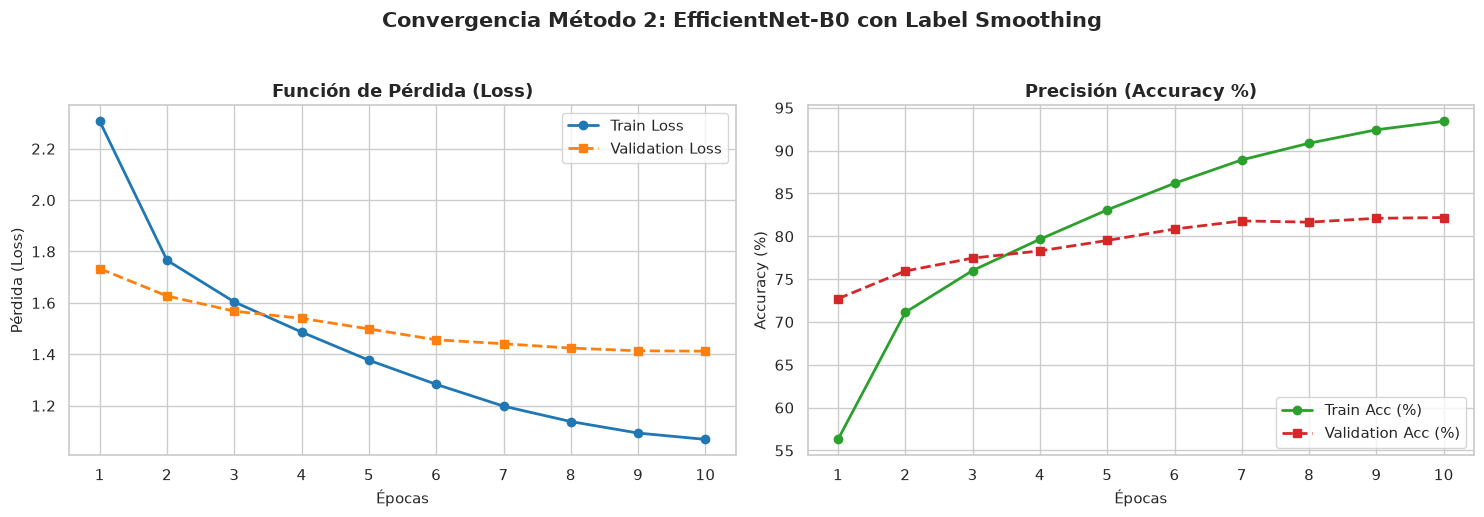

In [6]:
# Curvas de convergencia para ambos métodos
fig1, _ = plot_convergence_curves(history_baseline, title="Convergencia Método 1: ResNet-18 Baseline")
plt.show()

fig2, _ = plot_convergence_curves(history_advanced, title="Convergencia Método 2: EfficientNet-B0 con Label Smoothing")
plt.show()


---
### 5. Métricas de Desempeño y Comparación en Test (Sección 5.3)
Evaluación formal sobre el conjunto de prueba independiente ($25,250$ imágenes de prueba).
Métricas calculadas:
* **Top-1 Accuracy**
* **Top-5 Accuracy**
* **Precision Macro & Weighted**
* **Recall Macro & Weighted**
* **F1-Score Macro & Weighted**


In [7]:
# Inferencia y cálculo de métricas en conjunto de test
preds_m1, probs_m1, targets_m1 = trainer_baseline.predict(test_loader)
metrics_m1 = compute_classification_metrics(targets_m1, preds_m1, y_probs=probs_m1, class_names=class_names)

preds_m2, probs_m2, targets_m2 = trainer_advanced.predict(test_loader)
metrics_m2 = compute_classification_metrics(targets_m2, preds_m2, y_probs=probs_m2, class_names=class_names)

# Tabla comparativa formal (para el reporte IEEE)
comparison_df = pd.DataFrame({
    "Métrica": ["Top-1 Accuracy (%)", "Top-5 Accuracy (%)", "Precision Macro (%)", "Recall Macro (%)", "F1-Score Macro (%)"],
    "Método 1 (ResNet-18)": [
        metrics_m1["accuracy"] * 100,
        metrics_m1.get("top5_accuracy", 0) * 100,
        metrics_m1["precision_macro"] * 100,
        metrics_m1["recall_macro"] * 100,
        metrics_m1["f1_macro"] * 100,
    ],
    "Método 2 (EfficientNet-B0)": [
        metrics_m2["accuracy"] * 100,
        metrics_m2.get("top5_accuracy", 0) * 100,
        metrics_m2["precision_macro"] * 100,
        metrics_m2["recall_macro"] * 100,
        metrics_m2["f1_macro"] * 100,
    ]
})
print("="*65)
print(" TABLA COMPARATIVA DE DESEMPEÑO - CONJUNTO DE PRUEBA")
print("="*65)
print(comparison_df.to_string(index=False))


 TABLA COMPARATIVA DE DESEMPEÑO - CONJUNTO DE PRUEBA
            Métrica  Método 1 (ResNet-18)  Método 2 (EfficientNet-B0)
 Top-1 Accuracy (%)             66.510891                   87.152475
 Top-5 Accuracy (%)             88.946535                   97.548515
Precision Macro (%)             68.577710                   87.136527
   Recall Macro (%)             66.510891                   87.152475
 F1-Score Macro (%)             66.075630                   87.092186


[Visualización] Mostrando las primeras 20 clases de 101 para legibilidad.


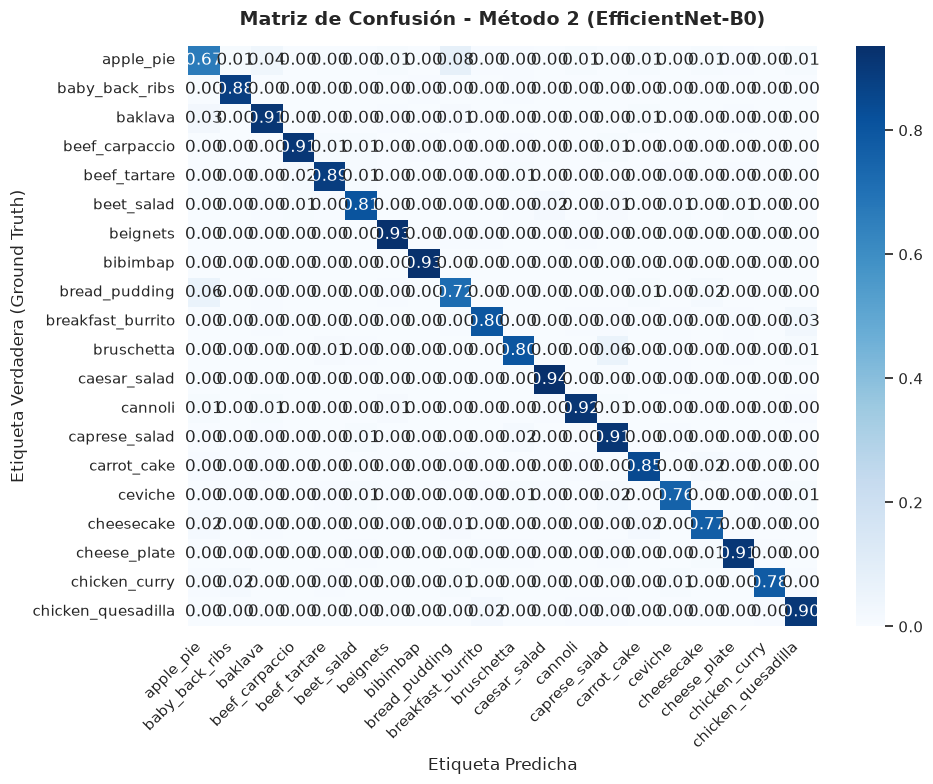

In [8]:
# Matriz de Confusión Normalizada
fig, ax = plot_confusion_matrix(targets_m2, preds_m2, class_names=class_names, title="Matriz de Confusión - Método 2 (EfficientNet-B0)")
plt.show()


---
### 6. Interpretabilidad y Análisis del Espacio Latente (Sección 5.5)
1. **Reducción de Dimensionalidad (t-SNE / PCA):** Se proyectan las representaciones vectoriales del espacio latente (penúltima capa) a 2D para evaluar separabilidad de clases y posibles solapamientos gastronómicos.
2. **Grad-CAM (Gradient-weighted Class Activation Mapping):** Mapas de calor visuales que indican qué regiones de los alimentos impulsan la predicción del modelo.


[Interpretabilidad] Aplicando reducción TSNE a 600 muestras con dimensión 1280...


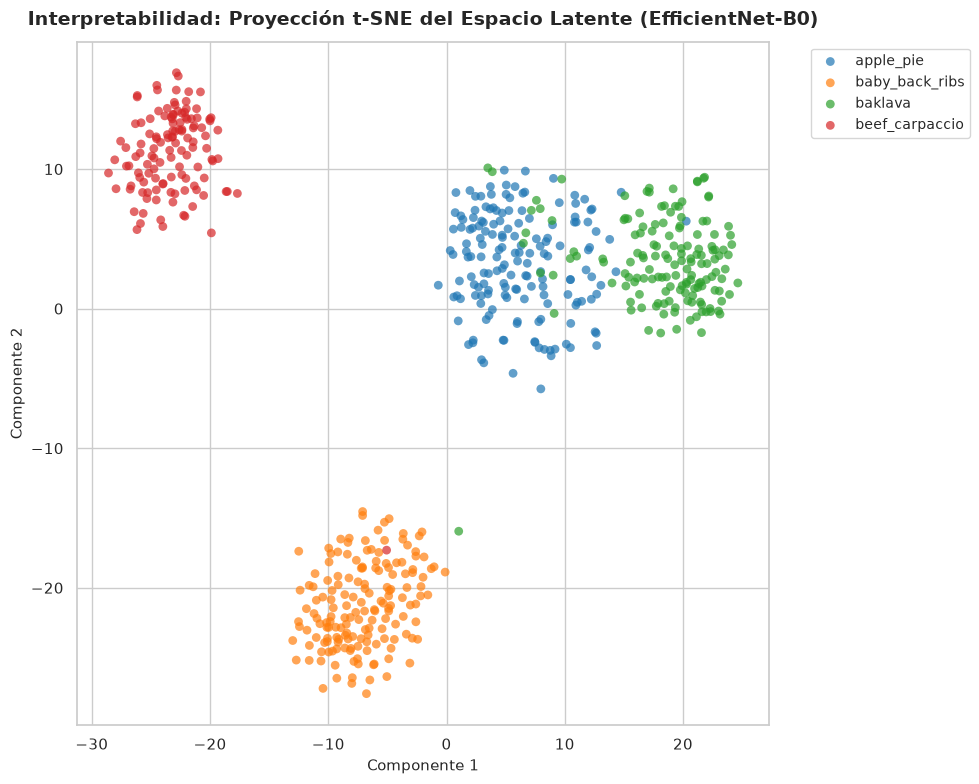

In [11]:
import importlib
import visualize
importlib.reload(visualize)
from visualize import plot_latent_space
# Proyección t-SNE de las características del espacio latente
feats_m2, labels_m2 = extract_torch_embeddings(model_advanced, test_loader, hw_info["device"], max_batches=15)

plot_latent_space(
    features=feats_m2,
    labels=labels_m2,
    class_names=class_names,
    method="tsne",
    n_samples=600,
    title="Interpretabilidad: Proyección t-SNE del Espacio Latente (EfficientNet-B0)"
)
plt.show()


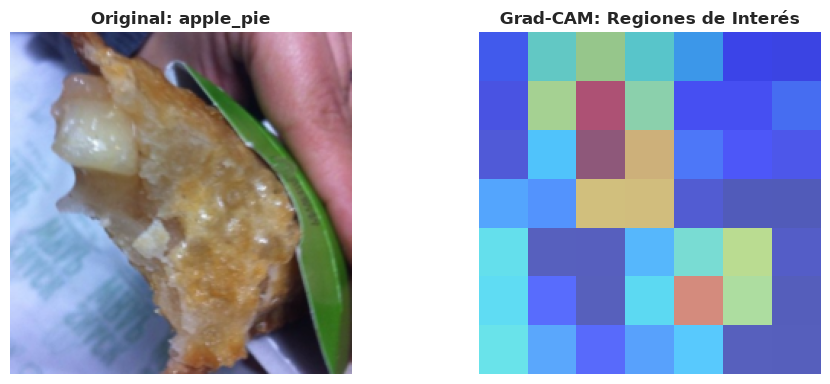

In [12]:
# Interpretabilidad Visual con Grad-CAM
grad_cam = SimpleGradCAM(model_advanced, model_advanced.backbone.features[-1])

# Seleccionar un ejemplo de test
sample_img, sample_lbl = next(iter(test_loader))
sample_img_gpu = sample_img[0:1].to(hw_info["device"])
heatmap = grad_cam.generate_heatmap(sample_img_gpu, target_class=sample_lbl[0].item())

# Visualizar original vs mapa de activación
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
raw_img = sample_img[0].permute(1, 2, 0).numpy()
raw_img = np.clip(raw_img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406], 0, 1)
plt.imshow(raw_img)
plt.title(f"Original: {class_names[sample_lbl[0].item()]}", fontweight='bold')
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(raw_img)
plt.imshow(heatmap, cmap="jet", alpha=0.5)
plt.title("Grad-CAM: Regiones de Interés", fontweight='bold')
plt.axis("off")
plt.tight_layout()
plt.show()


---
### 7. Estudio de Ablación (Sección 6.1)
Se evalúa el impacto de la técnica de regularización:
* **Configuración A:** Transfer Learning con Fine-Tuning completo (todas las capas entrenables).
* **Configuración B:** Feature Extraction puro (Backbone congelado, solo cabezal entrenable).
Este estudio permite cuantificar experimentalmente cuánto valor aporta la adaptación de capas profundas frente a pesos fijos de ImageNet.


In [14]:
# Estudio de Ablación: Backbone Congelado vs Fine-Tuning Completo
model_frozen = FoodVisionBaseline(num_classes=101, pretrained=True, freeze_backbone=True)
opt_frozen = torch.optim.Adam(filter(lambda p: p.requires_grad, model_frozen.parameters()), lr=1e-3)
trainer_frozen = Trainer(model_frozen, opt_frozen, device=hw_info["device"], use_amp=hw_info["use_amp"], checkpoint_dir=CHECKPOINTS_DIR, model_name="ablation_frozen")

hist_frozen = trainer_frozen.fit(train_loader, val_loader, epochs=3)

print("[Ablación] Desempeño con Backbone Congelado:")
print(f"Mejor Val Acc: {max(hist_frozen['val_acc'])*100:.2f}%")
print(f"Mejor Val Acc con Fine-Tuning Completo: {max(history_baseline['val_acc'])*100:.2f}%")


[FoodVisionBaseline] Backbone ResNet-18 congelado. Solo el cabezal se entrenará.

[Trainer] Iniciando entrenamiento por 3 épocas...
[Trainer] Dispositivo: cuda | Mixed Precision (AMP): True



Training:   0%|          | 0/1066 [00:00<?, ?it/s]

Época [01/03] (23.1s) | LR: 0.001000 | Train Loss: 3.1536 - Acc: 27.93% | Val Loss: 2.2172 - Acc: 46.13%
  --> ¡Nuevo mejor modelo guardado en /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/ablation_frozen.pt! (Val Acc: 46.13%)


Training:   0%|          | 0/1066 [00:00<?, ?it/s]

Época [02/03] (22.7s) | LR: 0.001000 | Train Loss: 2.6222 - Acc: 37.00% | Val Loss: 2.0482 - Acc: 49.37%
  --> ¡Nuevo mejor modelo guardado en /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/ablation_frozen.pt! (Val Acc: 49.37%)


Training:   0%|          | 0/1066 [00:00<?, ?it/s]

Época [03/03] (23.1s) | LR: 0.001000 | Train Loss: 2.5555 - Acc: 38.52% | Val Loss: 2.0220 - Acc: 50.14%
  --> ¡Nuevo mejor modelo guardado en /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/ablation_frozen.pt! (Val Acc: 50.14%)
[Trainer] Cargados los mejores pesos de /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/ablation_frozen.pt
[Ablación] Desempeño con Backbone Congelado:
Mejor Val Acc: 50.14%
Mejor Val Acc con Fine-Tuning Completo: 61.50%
